Saving diabetes (1).csv to diabetes (1) (1).csv
\n--- VERİ SETİNE GENEL BAKIŞ ---
Satır ve sütun sayısı: (768, 9)
\nSütunlar: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
\nİlk 5 satır:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148           72.0             35    169.5  33.6   
1            1       85           66.0             29    102.5  26.6   
2            8      183           64.0             32    169.5  23.3   
3            1       89           66.0             23     94.0  28.1   
4            0      137           40.0             35    168.0  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
\nEksik değer sayıları:
Pregnancies  

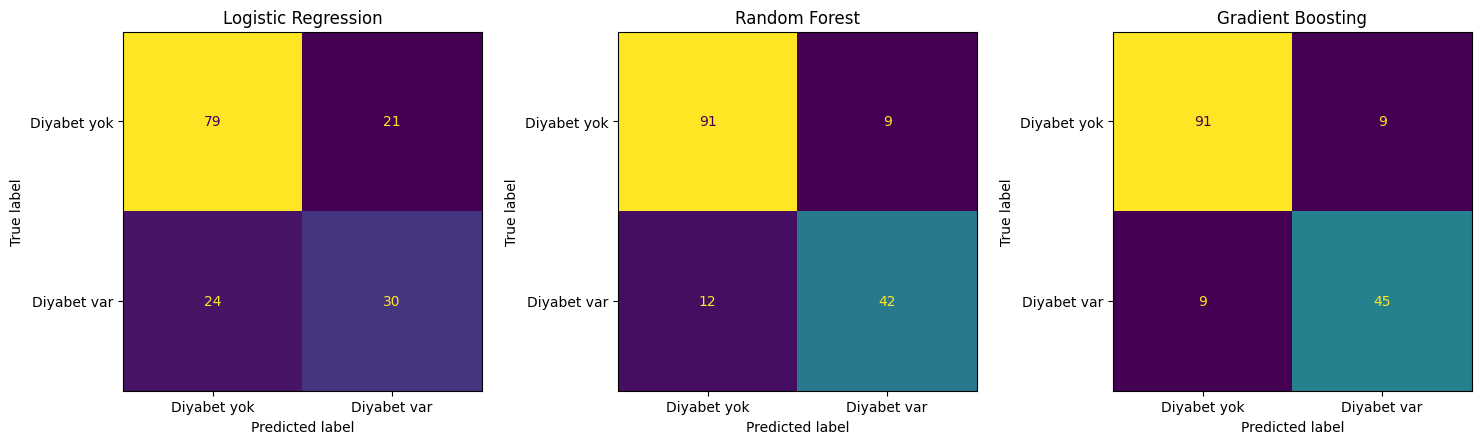

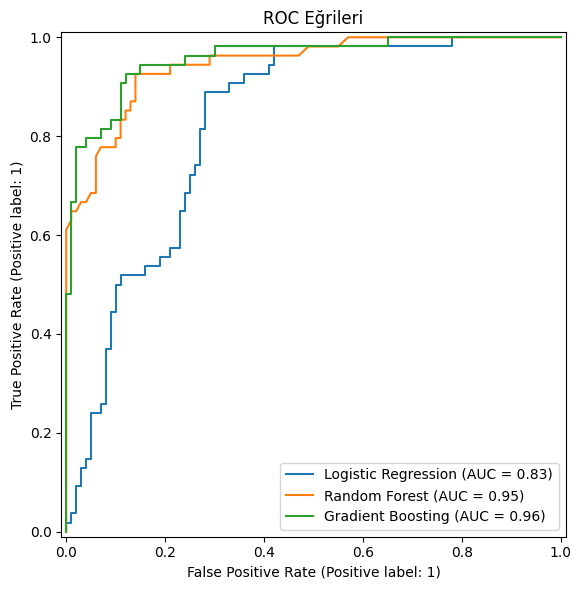

\n--- Random Forest: ÖZELLİK ÖNEMLERİ ---
Insulin                     36.02%
Glucose                     16.97%
SkinThickness               13.98%
BMI                          8.61%
Age                          7.65%
DiabetesPedigreeFunction     7.09%
BloodPressure                4.91%
Pregnancies                  4.77%


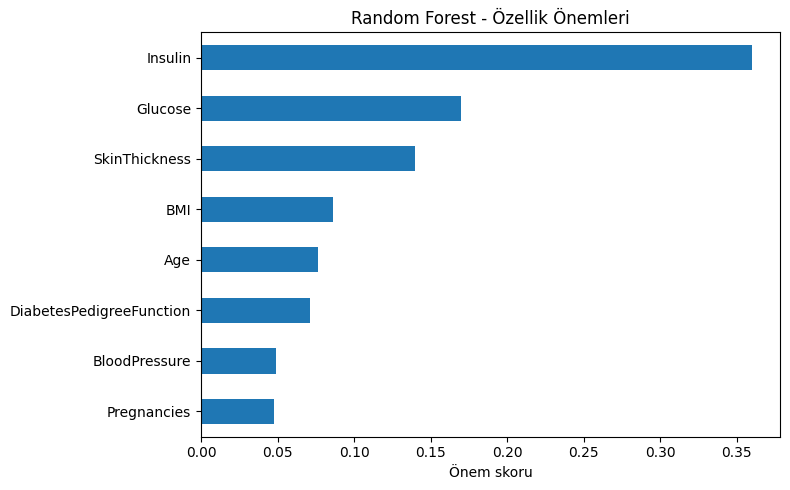

\n--- Gradient Boosting: ÖZELLİK ÖNEMLERİ ---
Insulin                     69.82%
Glucose                     12.09%
Age                          4.27%
SkinThickness                4.25%
BMI                          3.69%
DiabetesPedigreeFunction     3.06%
Pregnancies                  1.54%
BloodPressure                1.28%


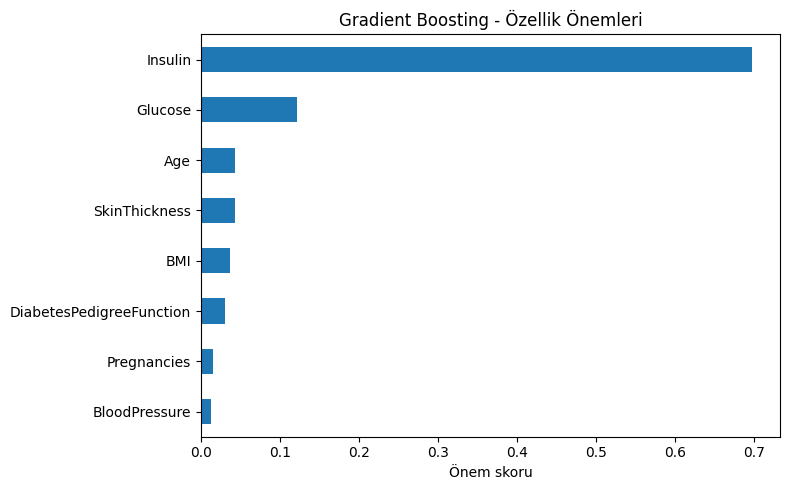

\n--- GRADIENT BOOSTING: DİYABETLİ SINIF ÖZETİ ---
Test kümesindeki Outcome=1 sayısı: 54
Doğru yakalanan Outcome=1 sayısı: 45
Kaçırılan Outcome=1 sayısı: 9
\nÖNEMLİ: Bunlar yalnızca bu veri seti ve bu rastgele test bölmesi için elde edilen eğitim amaçlı sonuçlardır.
Bu model tıbbi tanı koymak için kullanılmamalıdır.


In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay
)

# 1) CSV dosyasını yükle
try:
    from google.colab import files
    uploaded = files.upload()
    file_name = next(iter(uploaded))
except ImportError:
    file_name = "diabetes (1).csv"  # CSV dosyasını bu kodla aynı klasöre koy

df = pd.read_csv(file_name)

print("\\n--- VERİ SETİNE GENEL BAKIŞ ---")
print("Satır ve sütun sayısı:", df.shape)
print("\\nSütunlar:", df.columns.tolist())
print("\\nİlk 5 satır:")
print(df.head())
print("\\nEksik değer sayıları:")
print(df.isna().sum())
print("\\nOutcome sınıf dağılımı (0=diabet yok, 1=diabet var):")
print(df["Outcome"].value_counts().sort_index())
print("\\nSınıf yüzdeleri:")
print((df["Outcome"].value_counts(normalize=True).sort_index() * 100).round(2))

# 2) Özellikler ve hedef
target = "Outcome"
X = df.drop(columns=[target]).copy()
y = df[target].copy()

# Bazı Pima veri seti sürümlerinde bu ölçümlerdeki 0 değerleri
# eksik ölçüm anlamına gelebilir. Bu dosyada kaç tane olduğunu önce yazdırıyoruz.
zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
existing_zero_cols = [col for col in zero_as_missing if col in X.columns]

print("\\n--- ÖLÇÜM SÜTUNLARINDAKİ SIFIR SAYILARI ---")
print(X[existing_zero_cols].eq(0).sum())

# Yalnızca sıfır varsa eksik değer olarak ele al; bu CSV'de sıfır yoksa veri değişmez.
for col in existing_zero_cols:
    X.loc[X[col] == 0, col] = np.nan

# 3) Eğitim/test bölmesi: aynı test kümesiyle modelleri adil karşılaştır
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 4) Ön işleme: eksik değer doldurma ve ölçekleme yalnızca eğitim verisine fit edilir.
# Logistic Regression için ölçekleme kullanılır. Ağaç tabanlı modeller de aynı
# ön işleme akışından geçebilir; ölçekleme ağaç modelleri için zorunlu değildir.
preprocess = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, random_state=42, class_weight=None
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

results = []
fitted_models = {}
processed_feature_names = X.columns.tolist()

for model_name, model in models.items():
    pipe = Pipeline(steps=[
        ("preprocess", preprocess),
        ("model", model)
    ])
    pipe.fit(X_train, y_train)

    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]

    row = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "AUC": roc_auc_score(y_test, y_prob)
    }
    results.append(row)
    fitted_models[model_name] = pipe

    print(f"\\n--- {model_name} ---")
    print(classification_report(
        y_test, y_pred, target_names=["Diyabet yok (0)", "Diyabet var (1)"],
        zero_division=0
    ))
    print("Karmaşıklık matrisi:")
    print(confusion_matrix(y_test, y_pred))

results_df = pd.DataFrame(results).set_index("Model")
print("\\n--- MODEL KARŞILAŞTIRMA TABLOSU ---")
print((results_df * 100).round(2).to_string())
print("\\nNot: Yukarıdaki tabloda AUC da yüzde olarak gösterildi. Sunumda AUC'yi 0-1 aralığında yazmak istersen aşağıdaki ham tabloyu kullan:")
print(results_df.round(4).to_string())

# 5) Karmaşıklık matrisi ve ROC eğrileri
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (model_name, pipe) in zip(axes, fitted_models.items()):
    ConfusionMatrixDisplay.from_estimator(
        pipe, X_test, y_test,
        display_labels=["Diyabet yok", "Diyabet var"],
        ax=ax, colorbar=False
    )
    ax.set_title(model_name)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 6))
for model_name, pipe in fitted_models.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, ax=ax, name=model_name)
ax.set_title("ROC Eğrileri")
plt.tight_layout()
plt.show()

# 6) Özellik önemleri: Random Forest ve Gradient Boosting için
# Bu skorlar modelin tahminlerinde özellikleri ne kadar kullandığını gösterir;
# tek başına nedensellik veya tıbbi kanıt anlamına gelmez.
for model_name in ["Random Forest", "Gradient Boosting"]:
    pipe = fitted_models[model_name]
    fitted_model = pipe.named_steps["model"]
    if hasattr(fitted_model, "feature_importances_"):
        importance = pd.Series(
            fitted_model.feature_importances_,
            index=processed_feature_names
        ).sort_values(ascending=False)

        print(f"\\n--- {model_name}: ÖZELLİK ÖNEMLERİ ---")
        print((importance * 100).round(2).astype(str).add("%").to_string())

        plt.figure(figsize=(8, 5))
        importance.sort_values().plot(kind="barh")
        plt.title(f"{model_name} - Özellik Önemleri")
        plt.xlabel("Önem skoru")
        plt.tight_layout()
        plt.show()

# 7) Gradient Boosting için kaç diyabetli test örneği yakalandı?
gb_pipe = fitted_models["Gradient Boosting"]
gb_pred = gb_pipe.predict(X_test)
actual_positive = int((y_test == 1).sum())
caught_positive = int(((y_test == 1) & (gb_pred == 1)).sum())
missed_positive = int(((y_test == 1) & (gb_pred == 0)).sum())

print("\\n--- GRADIENT BOOSTING: DİYABETLİ SINIF ÖZETİ ---")
print("Test kümesindeki Outcome=1 sayısı:", actual_positive)
print("Doğru yakalanan Outcome=1 sayısı:", caught_positive)
print("Kaçırılan Outcome=1 sayısı:", missed_positive)
print("\\nÖNEMLİ: Bunlar yalnızca bu veri seti ve bu rastgele test bölmesi için elde edilen eğitim amaçlı sonuçlardır.")
print("Bu model tıbbi tanı koymak için kullanılmamalıdır.")
